# Vehicle Insurance Cross-Sell Response Prediction

## Life cycle of the machine learning project
- Understanding the problem statement
- Data collection
- Data checks to perform
- Exploratory data analysis
- Data pre-processing (decisions for the pipeline)
- Model training
- Choose best model

## Framing
1. **Business objective:** raise the share of contacted customers who buy vehicle
   insurance, within a limited outreach budget.
2. **ML problem type:** supervised binary classification, P(Response = 1 | x), with a
   cost-sensitive decision threshold.
3. **Baseline:** majority class (and random targeting). Any model must beat it on lift
   and PR-AUC, not accuracy.
4. **Constraints:** explainable (SHAP), fair across gender, simple to serve, and
   reproducible with one command.
5. **Metrics:** PR-AUC (primary), ROC-AUC, recall, top-10% lift, calibration.

## 1) Problem statement
This project predicts whether an existing life-insurance policyholder will respond
positively to a vehicle-insurance offer (`Response` = 1). The real output is a calibrated
probability, so a limited outreach budget can go to the customers most likely to say yes.

## 2) Data collection
- Source: Bank insurance analytics case study
- Files: train_data_cross-sell.csv (labelled), test_data_cross-sell.csv (no Response)
- Target: Response (1 = interested, 0 = not interested)
- **Size:** train has 324,466 rows and 12 columns; test has 56,643 rows and 11 columns

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

train = pd.read_csv("data/train_data_cross-sell.csv", dtype={"id": str})
test = pd.read_csv("data/test_data_cross-sell.csv", dtype={"id": str})
print(train.shape, test.shape)
train.head()

(324466, 12) (56643, 11)


,id,Gender,Customer_Date_of_Birth,Driving_License,Customer_Residence_Sub_County,Previously_Insured,Vehicle_Year_of_Manufacture,Vehicle_Damage,Annual_Premium,Agent_name,Life_policy_start_date,Response
0,549771831,Male,"Monday, March 7, 1977",1,EMBAKASI,0,2020,Yes,38294,Jomo Kenyatta,"Thursday, December 21, 2023",1
1,373583351,Male,"Sunday, December 29, 2002",1,WESTLANDS,1,2020,No,28619,Obiero Ochieng,"Wednesday, June 28, 2023",0
2,933163655,Female,"Tuesday, August 23, 1994",1,DAGORETTI,1,2011,No,27496,Obiero Ochieng,"Saturday, December 9, 2023",0
3,698942186,Female,"Thursday, November 18, 1999",1,JUJA,0,2020,Yes,2630,Gitonga Mwangi,"Tuesday, July 25, 2023",0
4,515109822,Male,"Thursday, February 22, 2001",1,WESTLANDS,0,2015,Yes,23367,Obiero Ochieng,"Saturday, May 13, 2023",0


In [2]:
print("Train rows, columns:", train.shape)
print("Test rows, columns:", test.shape)

Train rows, columns: (324466, 12)
Test rows, columns: (56643, 11)


## 2.2 Dataset information

- **id**: unique ID for the customer (read as text, so it is not corrupted into scientific notation)
- **Gender**: gender of the customer -> (Male/Female)
- **Customer_Date_of_Birth**: customer date of birth (text like "Tuesday, April 15, 1980", converted to a date later)
- **Driving_License**: whether the customer has a driving licence -> (0 = no, 1 = yes)
- **Customer_Residence_Sub_County**: sub-county where the customer lives (many unique values)
- **Previously_Insured**: whether the customer already has vehicle insurance -> (0 = no, 1 = yes)
- **Vehicle_Year_of_Manufacture**: year the vehicle was manufactured
- **Vehicle_Damage**: whether the customer's vehicle has been damaged in the past -> (Yes/No)
- **Annual_Premium**: the amount the customer pays as premium in the year
- **Agent_name**: name of the life insurance sales agent who sold the policy (many unique values)
- **Life_policy_start_date**: effective date of the customer's life insurance policy (text, converted to a date later)
- **Response** (target, train file only): whether the customer is interested in vehicle insurance -> (1 = interested, 0 = not interested)

## 3) Data checks to perform
- Check missing values
- Check duplicates
- Check data types
- Check the number of unique values in each column
- Check statistics of the data set
- Check the categories present in the categorical columns
- Check dates parse correctly and values are plausible (ages, vehicle years, premiums)

### 3.1 Check missing values

In [3]:
train.isna().sum()

id                               0
Gender                           0
Customer_Date_of_Birth           0
Driving_License                  0
Customer_Residence_Sub_County    0
Previously_Insured               0
Vehicle_Year_of_Manufacture      0
Vehicle_Damage                   0
Annual_Premium                   0
Agent_name                       0
Life_policy_start_date           0
Response                         0
dtype: int64

**Observation:** None of the 12 columns has a missing value (all counts are 0), so no imputation is needed for the train set.

### 3.2 Check duplicates

In [4]:
print("Duplicate rows:", train.duplicated().sum())
print("Duplicate ids:", train["id"].duplicated().sum())
print("Duplicates ignoring id:", train.drop(columns="id").duplicated().sum())

Duplicate rows: 0
Duplicate ids: 70
Duplicates ignoring id: 0


**Observation:**
- There are 0 fully duplicated rows, and 0 duplicates when `id` is ignored, so no customer record is repeated.
- However, 70 `id` values appear more than once (324,396 unique ids across 324,466 rows). Since the rows differ in every other column, these are not duplicate customers but repeated ids.
- This confirms that `id` cannot be trusted for deduplication or joins. It will be dropped from the model features and kept only to identify records.

### 3.3 Check data types

In [5]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 324466 entries, 0 to 324465
Data columns (total 12 columns):
 #   Column                         Non-Null Count   Dtype
---  ------                         --------------   -----
 0   id                             324466 non-null  str  
 1   Gender                         324466 non-null  str  
 2   Customer_Date_of_Birth         324466 non-null  str  
 3   Driving_License                324466 non-null  int64
 4   Customer_Residence_Sub_County  324466 non-null  str  
 5   Previously_Insured             324466 non-null  int64
 6   Vehicle_Year_of_Manufacture    324466 non-null  int64
 7   Vehicle_Damage                 324466 non-null  str  
 8   Annual_Premium                 324466 non-null  int64
 9   Agent_name                     324466 non-null  str  
 10  Life_policy_start_date         324466 non-null  str  
 11  Response                       324466 non-null  int64
dtypes: int64(5), str(7)
memory usage: 29.7 MB


**Observation:**
- 5 columns are integers (`Driving_License`, `Previously_Insured`, `Vehicle_Year_of_Manufacture`, `Annual_Premium`, `Response`) and 7 are text.
- `Customer_Date_of_Birth` and `Life_policy_start_date` are stored as long text strings and must be converted to dates (done in 3.7).
- `id` is kept as text so it is not turned into scientific notation.
- `Gender`, `Vehicle_Damage`, sub-county and agent are categorical and will be encoded in the pipeline.

### 3.4 Check the number of unique values of each column

In [6]:
train.nunique()

id                               324396
Gender                                2
Customer_Date_of_Birth            21108
Driving_License                       2
Customer_Residence_Sub_County        53
Previously_Insured                    2
Vehicle_Year_of_Manufacture          14
Vehicle_Damage                        2
Annual_Premium                    47027
Agent_name                          155
Life_policy_start_date              290
Response                              2
dtype: int64

**Observation:**
- `Gender`, `Driving_License`, `Previously_Insured`, `Vehicle_Damage` and `Response` are binary (2 values each).
- `Vehicle_Year_of_Manufacture` has only 14 values (2009 to 2022), so it behaves like a small ordered category.
- `Customer_Residence_Sub_County` has 53 values and `Agent_name` has 155. These are high-cardinality categoricals, so one-hot encoding would add many columns. They will be target-encoded inside cross-validation folds.
- `Life_policy_start_date` has 290 unique dates, which gives enough time points for a temporal split.
- `Annual_Premium` (47,027 values) and `Customer_Date_of_Birth` (21,108 values) are effectively continuous.

### 3.5 Check statistics of the data set

In [7]:
train.describe()

,Driving_License,Previously_Insured,Vehicle_Year_of_Manufacture,Annual_Premium,Response
count,324466.000000,324466.000000,324466.000000,324466.000000,324466.000000
mean,0.997938,0.457971,2015.048584,30570.897339,0.122805
std,0.045361,0.498231,3.745267,17196.763434,0.328214
min,0.000000,0.000000,2009.000000,2630.000000,0.000000
25%,1.000000,0.000000,2012.000000,24404.000000,0.000000
50%,1.000000,0.000000,2015.000000,31661.000000,0.000000
75%,1.000000,1.000000,2018.000000,39393.000000,0.000000
max,1.000000,1.000000,2022.000000,540165.000000,1.000000


**Observation:**
- `Response` has a mean of 0.123, so about 12.3% of customers are interested (the class imbalance is examined in section 4).
- `Driving_License` has a mean of 0.998, so almost everyone has a licence. It is nearly constant and will probably add little predictive value.
- `Previously_Insured` has a mean of 0.458, so about 46% already have vehicle insurance.
- `Vehicle_Year_of_Manufacture` runs from 2009 to 2022 (mean about 2015), which is plausible.
- `Annual_Premium` has a median of 31,661, and 75% of values are below 39,393, but the maximum is 540,165, more than 13 times the 75th percentile. These high outliers need a decision (cap, log-transform, or rely on tree models, which handle them well). The minimum is 2,630.

### 3.6 Check the categories in the categorical columns

In [8]:
low_card = ["Gender", "Driving_License", "Previously_Insured", "Vehicle_Damage", "Response"]
for col in low_card:
    print(col, "->", train[col].value_counts(dropna=False).to_dict())

for col in ["Customer_Residence_Sub_County", "Agent_name"]:
    print(f"\n{col}: {train[col].nunique()} unique")
    print(sorted(train[col].dropna().unique())[:60])

Gender -> {'Male': 175182, 'Female': 149284}
Driving_License -> {1: 323797, 0: 669}
Previously_Insured -> {0: 175870, 1: 148596}
Vehicle_Damage -> {'Yes': 163912, 'No': 160554}
Response -> {0: 284620, 1: 39846}

Customer_Residence_Sub_County: 53 unique
['ATHI RIVER', 'BONDO', 'BUMULA', 'BUNGOMA SOUTH', 'BURETI', 'DAGORETTI', 'EMBAKASI', 'IGEMBE CENTRAL', 'IMENTI SOUTH', 'ISINYA', 'JUJA', 'KABETE', 'KAJIADO NORTH', 'KAKAMEGA NORTH', 'KAMUKUNJI', 'KAPSERET', 'KASARANI', 'KIAMBAA', 'KILIFI SOUTH', 'KIMININI', 'KISAUNI', 'KISUMU EAST', 'KURIA WEST', 'KWANZA', "LANG'ATA", 'LIKONI', 'LUNGA LUNGA', 'MALINDI', 'MATHARE', 'NAIVASHA', 'NAKURU NORTH', 'NAKURU WEST', 'NAROK NORTH', 'NAROK SOUTH', 'NDHIWA', 'NJIRU', 'NJORO', 'NYALI', 'RONGAI', 'RUIRU', 'SAMBURU', 'SIAYA', 'SOTIK', 'SOY', 'STAREHE', 'THARAKA-NITHI', 'THIKA WEST', 'TRANS MARA WEST', 'TRANS NZOIA EAST', 'TRANS NZOIA WEST', 'TURBO', 'TURKANA WEST', 'WESTLANDS']

Agent_name: 155 unique
['Achieng Kwamboka', 'Akinyi Chepkorir', 'Akoth Che

**Observation:**
- `Gender`: Male 175,182 (54%) and Female 149,284 (46%), so the groups are reasonably balanced for the fairness check.
- `Driving_License`: 323,797 have a licence and only 669 (0.2%) do not.
- `Previously_Insured`: 175,870 not insured and 148,596 insured.
- `Vehicle_Damage`: Yes 163,912 and No 160,554, almost evenly split.
- `Response`: 284,620 not interested (0) and 39,846 interested (1), about 7 non-interested customers for every interested one. Accuracy would be misleading here, because predicting "not interested" for everyone scores about 87.7%. This supports using PR-AUC as the primary metric.
- Sub-county names (53) are all upper case and consistently spelled. The agent names that were printed (first 60 of 155) also look consistently formatted, with no obvious case or spacing differences.

### 3.7 Check that dates parse and values are plausible

In [9]:
fmt = "%A, %B %d, %Y"
for df in (train, test):
    df["Customer_Date_of_Birth"] = pd.to_datetime(df["Customer_Date_of_Birth"], format=fmt, errors="coerce")
    df["Life_policy_start_date"] = pd.to_datetime(df["Life_policy_start_date"], format=fmt, errors="coerce")
    df["age"] = (df["Life_policy_start_date"] - df["Customer_Date_of_Birth"]).dt.days / 365.25
    df["vehicle_age"] = df["Life_policy_start_date"].dt.year - df["Vehicle_Year_of_Manufacture"]

print("Unparsed dates:\n", train[["Customer_Date_of_Birth", "Life_policy_start_date"]].isna().sum(), "\n")
print("Policy start range:", train["Life_policy_start_date"].min(), "to", train["Life_policy_start_date"].max())
print("Age < 18:", (train["age"] < 18).sum(), "| Age > 90:", (train["age"] > 90).sum())
print("Negative vehicle age:", (train["vehicle_age"] < 0).sum(), "| Vehicle age > 40:", (train["vehicle_age"] > 40).sum())
print("Annual_Premium <= 0:", (train["Annual_Premium"] <= 0).sum())
train[["age", "vehicle_age", "Annual_Premium"]].describe()

Unparsed dates:
 Customer_Date_of_Birth    0
Life_policy_start_date    0
dtype: int64 

Policy start range: 2023-03-24 00:00:00 to 2024-01-07 00:00:00
Age < 18: 0 | Age > 90: 0
Negative vehicle age: 0 | Vehicle age > 40: 0
Annual_Premium <= 0: 0


,age,vehicle_age,Annual_Premium
count,324466.000000,324466.000000,324466.000000
mean,38.373297,7.975437,30570.897339
std,15.496602,3.748249,17196.763434
min,18.699521,1.000000,2630.000000
25%,24.156057,5.000000,24404.000000
50%,35.791923,8.000000,31661.000000
75%,48.943874,11.000000,39393.000000
max,84.895277,15.000000,540165.000000


**Observation:**
- All dates in both columns parsed successfully (0 unparsed).
- Life policies start between 24 March 2023 and 7 January 2024, about 9.5 months of data. A temporal split will therefore cover short windows (for example train on the earliest months, validate and test on the latest), and drift between them will be checked.
- Customer age at policy start ranges from 18.7 to 84.9 years (mean 38.4, median 35.8), so there are no minors or impossible ages.
- Vehicle age ranges from 1 to 15 years (mean 8.0) with no negative values.
- All annual premiums are positive. The only extreme values are the high outliers noted in 3.5.

### 3.8 Data quality note
The checks found no missing values, no duplicated rows, no unparsed dates and no
impossible ages or vehicle years, so this dataset is much cleaner than typical
real-world data. [Source of the explanation, e.g. "As explained in the case study /
by the data provider"], the data was anonymised and prepared before release, which
removed most obvious errors.

The checks still showed issues that the pipeline must handle:
- Dates stored as long text strings (parsed to dates, then converted to age and vehicle age)
- 70 repeated customer ids, so ids cannot be used for deduplication or joins
- High-cardinality categoricals (53 sub-counties, 155 agents) needing in-fold target encoding
- Class imbalance (12.3% positive), which rules out accuracy as a metric
- Strong right-skew and outliers in `Annual_Premium` (maximum 540,165)
- A near-constant `Driving_License` column (99.8% = 1)
- A short time window (about 9.5 months), which limits the temporal split

### 3.9 Data checks on the test set
The test file has no `Response`, so these checks cover structure, quality, overlap with train and how it compares with train. They show whether the model will meet anything at prediction time that it never saw in training.

#### 3.9.1 Structure and missing values

In [10]:
print("Columns only in train:", set(train.columns) - set(test.columns))
print("Columns only in test: ", set(test.columns) - set(train.columns))
print("\nMissing values in test:")
print(test.isna().sum())

Columns only in train: {'Response'}
Columns only in test:  set()

Missing values in test:
id                               0
Gender                           0
Customer_Date_of_Birth           0
Driving_License                  0
Customer_Residence_Sub_County    0
Previously_Insured               0
Vehicle_Year_of_Manufacture      0
Vehicle_Damage                   0
Annual_Premium                   0
Agent_name                       0
Life_policy_start_date           0
age                              0
vehicle_age                      0
dtype: int64


#### 3.9.2 Duplicates, id overlap with train, and date parsing

In [11]:
print("Duplicate rows in test:", test.duplicated().sum())
print("Duplicate ids within test:", test["id"].duplicated().sum())
print("Test ids that also appear in train:", test["id"].isin(train["id"]).sum())
print("\nUnparsed dates in test:")
print(test[["Customer_Date_of_Birth", "Life_policy_start_date"]].isna().sum())

Duplicate rows in test: 0
Duplicate ids within test: 13
Test ids that also appear in train: 0

Unparsed dates in test:
Customer_Date_of_Birth    0
Life_policy_start_date    0
dtype: int64


#### 3.9.3 Data types, unique values and statistics

In [12]:
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 56643 entries, 0 to 56642
Data columns (total 13 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   id                             56643 non-null  str           
 1   Gender                         56643 non-null  str           
 2   Customer_Date_of_Birth         56643 non-null  datetime64[us]
 3   Driving_License                56643 non-null  int64         
 4   Customer_Residence_Sub_County  56643 non-null  str           
 5   Previously_Insured             56643 non-null  int64         
 6   Vehicle_Year_of_Manufacture    56643 non-null  int64         
 7   Vehicle_Damage                 56643 non-null  str           
 8   Annual_Premium                 56643 non-null  int64         
 9   Agent_name                     56643 non-null  str           
 10  Life_policy_start_date         56643 non-null  datetime64[us]
 11  age                       

In [13]:
test.nunique()

id                               56630
Gender                               2
Customer_Date_of_Birth           15898
Driving_License                      2
Customer_Residence_Sub_County       53
Previously_Insured                   2
Vehicle_Year_of_Manufacture         14
Vehicle_Damage                       2
Annual_Premium                   25638
Agent_name                         125
Life_policy_start_date             290
age                              17781
vehicle_age                         15
dtype: int64

In [14]:
test.describe()

,Customer_Date_of_Birth,Driving_License,Previously_Insured,Vehicle_Year_of_Manufacture,Annual_Premium,Life_policy_start_date,age,vehicle_age
count,56643,56643.000000,56643.000000,56643.000000,56643.000000,56643,56643.000000,56643.000000
mean,1985-03-31 16:22:58.910015,0.997475,0.459580,2015.056494,30527.111435,2023-08-15 03:19:40.043430,38.372227,7.966757
min,1938-10-09 00:00:00,0.000000,0.000000,2009.000000,2630.000000,2023-03-24 00:00:00,18.781656,1.000000
25%,1974-09-14 12:00:00,1.000000,0.000000,2012.000000,24407.500000,2023-06-03 00:00:00,24.125941,5.000000
50%,1988-01-02 00:00:00,1.000000,0.000000,2015.000000,31711.000000,2023-08-15 00:00:00,35.641342,8.000000
75%,1999-05-28 12:00:00,1.000000,1.000000,2018.000000,39432.000000,2023-10-27 00:00:00,49.010267,11.000000
max,2004-07-08 00:00:00,1.000000,1.000000,2022.000000,540165.000000,2024-01-07 00:00:00,84.870637,15.000000
std,NaN,0.050182,0.498368,3.733323,17306.856741,NaN,15.544667,3.734938


#### 3.9.4 Categories, and categories the model has never seen

In [15]:
for col in ["Gender", "Driving_License", "Previously_Insured", "Vehicle_Damage"]:
    print(col, "->", test[col].value_counts(dropna=False).to_dict())

for col in ["Customer_Residence_Sub_County", "Agent_name"]:
    unseen = set(test[col].dropna()) - set(train[col].dropna())
    n_rows = test[col].isin(unseen).sum()
    print(f"\n{col}: {len(unseen)} categories in test but not in train, covering {n_rows} test rows")
    if unseen:
        print(sorted(unseen))

Gender -> {'Male': 30907, 'Female': 25736}
Driving_License -> {1: 56500, 0: 143}
Previously_Insured -> {0: 30611, 1: 26032}
Vehicle_Damage -> {'Yes': 28501, 'No': 28142}

Customer_Residence_Sub_County: 0 categories in test but not in train, covering 0 test rows

Agent_name: 0 categories in test but not in train, covering 0 test rows


#### 3.9.5 Policy dates and plausibility in test

In [16]:
print("Train policy dates:", train["Life_policy_start_date"].min().date(), "to", train["Life_policy_start_date"].max().date())
print("Test policy dates: ", test["Life_policy_start_date"].min().date(), "to", test["Life_policy_start_date"].max().date())
print()
print("Test age < 18:", (test["age"] < 18).sum(), "| age > 90:", (test["age"] > 90).sum())
print("Test negative vehicle age:", (test["vehicle_age"] < 0).sum(), "| vehicle age > 40:", (test["vehicle_age"] > 40).sum())
print("Test Annual_Premium <= 0:", (test["Annual_Premium"] <= 0).sum())

Train policy dates: 2023-03-24 to 2024-01-07
Test policy dates:  2023-03-24 to 2024-01-07

Test age < 18: 0 | age > 90: 0
Test negative vehicle age: 0 | vehicle age > 40: 0
Test Annual_Premium <= 0: 0


#### 3.9.6 Train vs test, side by side

In [17]:
cols = ["age", "vehicle_age", "Annual_Premium", "Previously_Insured", "Driving_License"]
cmp = pd.DataFrame({"train_mean": train[cols].mean(), "test_mean": test[cols].mean()})
cmp["diff_%"] = (cmp["test_mean"] / cmp["train_mean"] - 1) * 100
cmp.round(3)

,train_mean,test_mean,diff_%
age,38.373,38.372,-0.003
vehicle_age,7.975,7.967,-0.109
Annual_Premium,30570.897,30527.111,-0.143
Previously_Insured,0.458,0.460,0.351
Driving_License,0.998,0.997,-0.046


**Observation (3.9):**
- The test file has no missing values and no duplicated rows. The only column in train and not in test is `Response`, as expected.
- 13 `id` values repeat within test, which is consistent with the repeated ids in train (70). None of the test ids appear in train, so the two files share no ids. Because ids are unreliable, this does not prove that no customer is in both files.
- All dates in test parsed. Test policies start between 24 March 2023 and 7 January 2024, exactly the same window as train. The unlabelled file is therefore not a later "future" set: it comes from the same period, so the temporal split has to be made inside the labelled data (see 4.5.1).
- There are no unseen categories. All 53 sub-counties in test, and all 125 agents in test (out of 155 in train), also appear in train, so the target encoder meets no new category when scoring this file. A fallback to the global response rate is still sensible for future data.
- Train and test agree closely: mean age 38.37 vs 38.37, vehicle age 7.98 vs 7.97, premium 30,571 vs 30,527 and `Previously_Insured` 0.458 vs 0.460, all within 0.4%. Test has no impossible ages (18.8 to 84.9) or vehicle ages (1 to 15), and every premium is positive.

## 4) Exploratory data analysis
Everything that uses `Response` is computed on **train only**. The test file has no labels, so it is used only to compare distributions (4.7).

### 4.0 Feature lists

In [18]:
target = "Response"
numeric_features = ["age", "vehicle_age", "Annual_Premium"]
binary_features = ["Driving_License", "Previously_Insured"]
categorical_features = ["Gender", "Vehicle_Damage", "Customer_Residence_Sub_County", "Agent_name"]

print(f"We have {len(numeric_features)} numerical features: {numeric_features}")
print(f"We have {len(binary_features)} binary features: {binary_features}")
print(f"We have {len(categorical_features)} categorical features: {categorical_features}")

We have 3 numerical features: ['age', 'vehicle_age', 'Annual_Premium']
We have 2 binary features: ['Driving_License', 'Previously_Insured']
We have 4 categorical features: ['Gender', 'Vehicle_Damage', 'Customer_Residence_Sub_County', 'Agent_name']


Explicit lists are used on purpose. Detecting categorical columns with `dtype == 'O'` (as in many tutorials) misses text columns in recent pandas versions, where they have the `str` dtype.

### 4.1 Target distribution

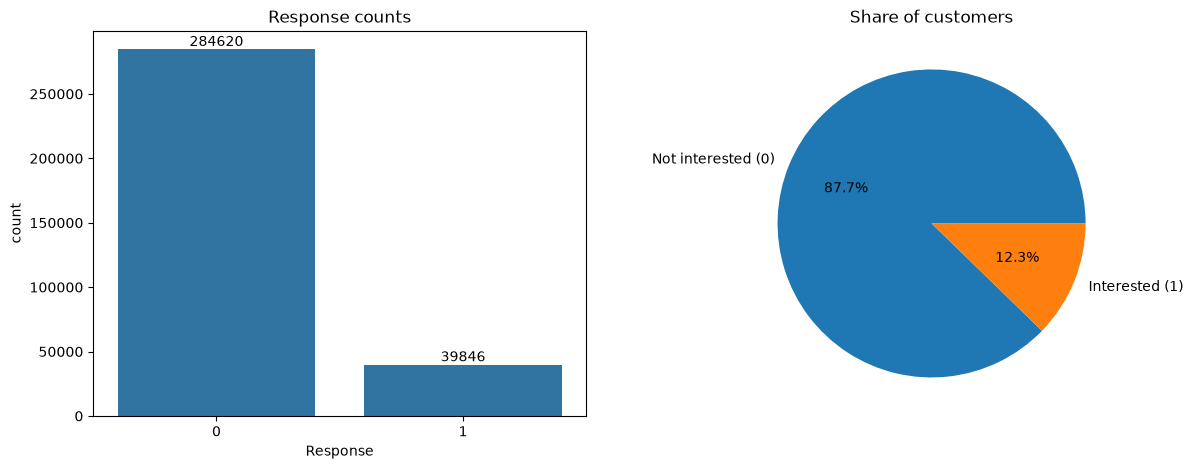

Imbalance: 7.1 not-interested customers for every interested one


In [19]:
f, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(x="Response", data=train, ax=ax[0])
for c in ax[0].containers:
    ax[0].bar_label(c)
ax[0].set_title("Response counts")
train["Response"].value_counts().sort_index().plot.pie(
    autopct="%1.1f%%", labels=["Not interested (0)", "Interested (1)"], ax=ax[1])
ax[1].set_ylabel("")
ax[1].set_title("Share of customers")
plt.show()

vc = train["Response"].value_counts()
print(f"Imbalance: {vc[0] / vc[1]:.1f} not-interested customers for every interested one")

**Insight:** 12.3% of customers are interested (39,846 of 324,466), about 7 non-interested customers for every interested one (7.1 : 1). A model that predicts "not interested" for everyone would be 87.7% accurate and find nobody, which is why accuracy is excluded and PR-AUC is the primary metric. The overall rate of 12.3% is also the baseline that lift is measured against.

### 4.2 Numeric features, split by Response

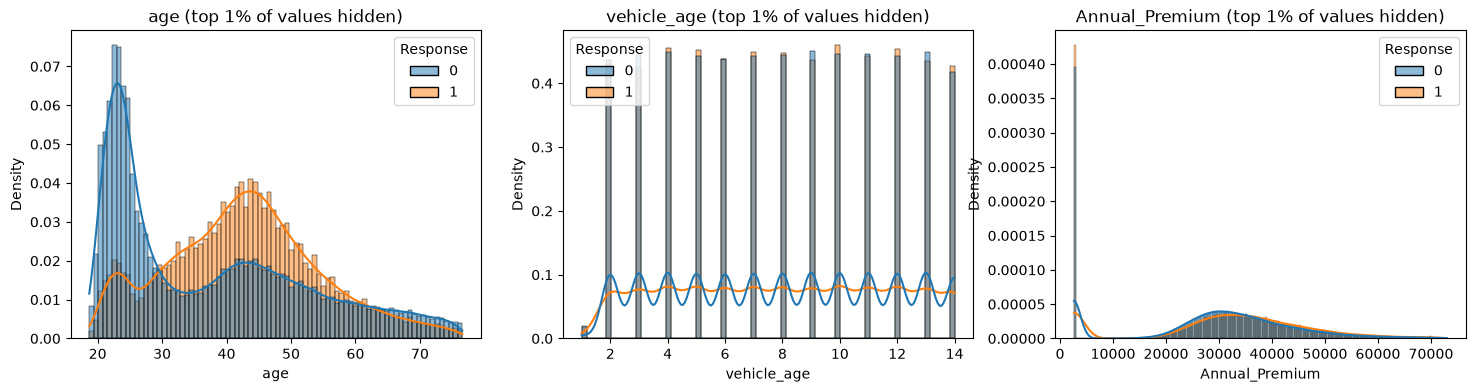

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, numeric_features):
    data = train[train[col] <= train[col].quantile(0.99)]   # clip the extreme tail so the shape is readable
    sns.histplot(data=data, x=col, hue="Response", kde=True, stat="density",
                 common_norm=False, ax=ax)
    ax.set_title(col + " (top 1% of values hidden)")
plt.show()

Each class is scaled separately (`common_norm=False`), so the small "interested" group is visible next to the large one.

**Insight:**
- **Age** separates the classes clearly. Non-interested customers peak sharply at about 22 to 24 years, while interested customers peak at about 42 to 45 years and are rare below 30.
- **Vehicle age** shows almost no difference between the classes. The spikes appear only because it takes whole-number values.
- **Annual premium** looks similar for both classes: a bell shape centred near 30,000, plus a spike at the minimum value of 2,630 (see 4.3).

### 4.3 Outliers

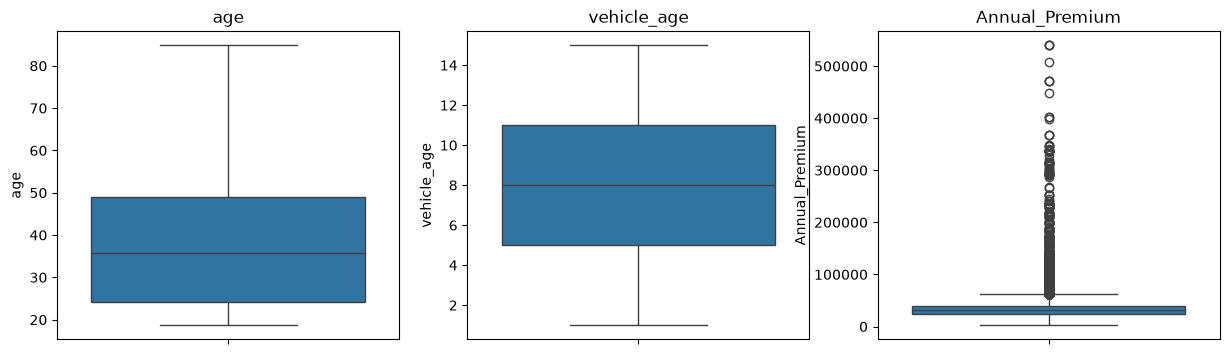

Annual_Premium upper fence (Q3 + 1.5*IQR): 61,876
Premiums above the fence: 8810 (2.72% of rows)
99th percentile: 73,021 | maximum: 540,165


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, numeric_features):
    sns.boxplot(y=train[col], ax=ax)
    ax.set_title(col)
plt.show()

q1, q3 = train["Annual_Premium"].quantile([0.25, 0.75])
fence = q3 + 1.5 * (q3 - q1)
n_out = (train["Annual_Premium"] > fence).sum()
print(f"Annual_Premium upper fence (Q3 + 1.5*IQR): {fence:,.0f}")
print(f"Premiums above the fence: {n_out} ({n_out / len(train):.2%} of rows)")
print(f"99th percentile: {train['Annual_Premium'].quantile(0.99):,.0f} | maximum: {train['Annual_Premium'].max():,}")

**Insight:**
- 8,810 premiums (2.7% of rows) lie above the upper fence of 61,876. The 99th percentile is 73,021, but the maximum is 540,165, so premium has a long, thin upper tail. Age and vehicle age have no outliers.
- Decision: leave premium as it is for the tree models. For Logistic Regression, cap it at the 99th percentile or log-transform it.
- The histogram in 4.2 also shows a large spike at the minimum premium of 2,630, and the premium decile chart in 4.4.3 has 9 bars instead of 10 because so many customers share that value. Check what it is with `(train["Annual_Premium"] == 2630).sum()`. If it is a minimum or default premium, a flag for it may be a useful feature.

### 4.4 Feature-wise analysis: response rate by category

#### 4.4.1 Low-cardinality features

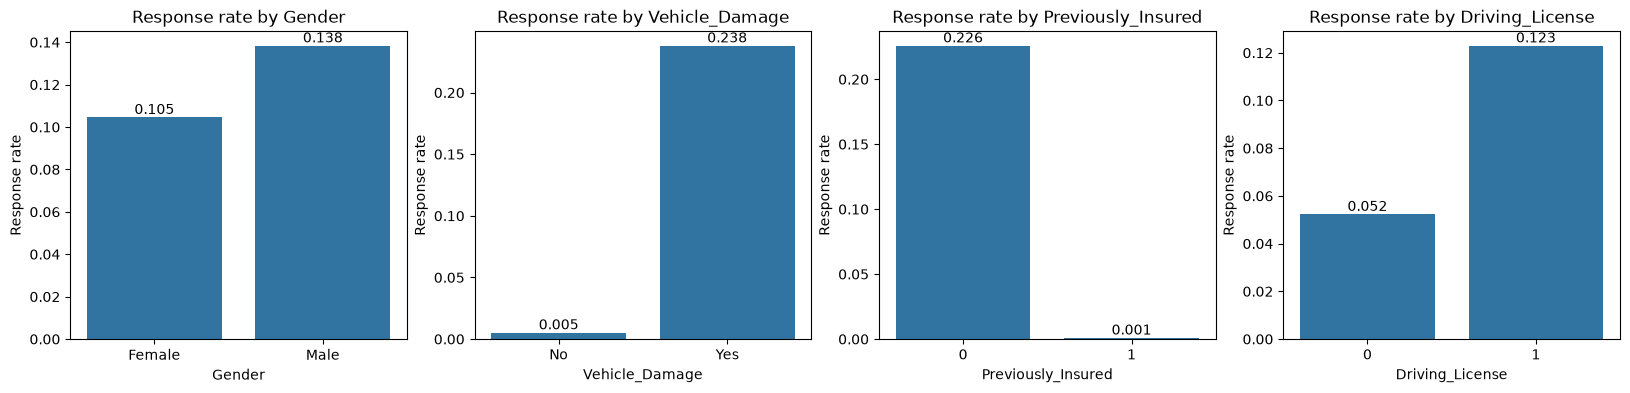

Customers per group:
  Gender {'Male': 175182, 'Female': 149284}
  Vehicle_Damage {'Yes': 163912, 'No': 160554}
  Previously_Insured {0: 175870, 1: 148596}
  Driving_License {1: 323797, 0: 669}


In [22]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, ["Gender", "Vehicle_Damage", "Previously_Insured", "Driving_License"]):
    rate = train.groupby(col)["Response"].mean()
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.3f")
    ax.set_title("Response rate by " + col)
    ax.set_ylabel("Response rate")
plt.show()

print("Customers per group:")
for col in ["Gender", "Vehicle_Damage", "Previously_Insured", "Driving_License"]:
    print(" ", col, train[col].value_counts().to_dict())

**Insight:**
- `Previously_Insured`: the response rate is 22.6% for customers without vehicle insurance and only 0.1% for those who already have it. Customers who are already insured almost never respond.
- `Vehicle_Damage`: 23.8% for "Yes" vs 0.5% for "No". Together with `Previously_Insured`, it is the strongest single signal.
- `Gender`: 13.8% for male vs 10.5% for female. This is the base-rate gap that the fairness check will build on.
- `Driving_License`: 12.3% with a licence vs 5.2% without, but only 669 customers (0.2%) have no licence, so treat that rate with caution.

#### 4.4.2 Interaction: vehicle damage and previous insurance

Response rate (rows: Vehicle_Damage, columns: Previously_Insured)


Previously_Insured,0,1
Vehicle_Damage,,
No,0.038,0.000
Yes,0.250,0.009


Customers in each cell


Previously_Insured,0,1
Vehicle_Damage,,
No,20388,140166
Yes,155482,8430


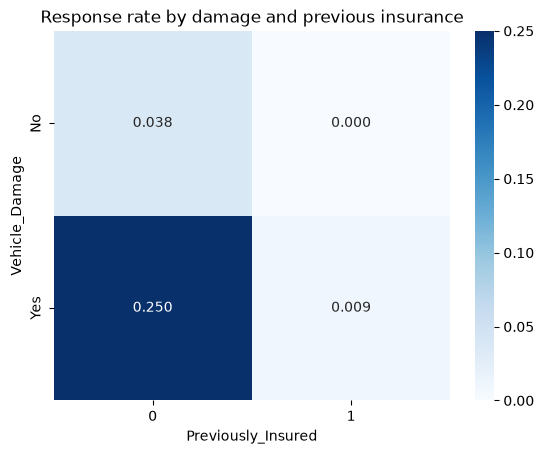

In [23]:
rates = pd.crosstab(train["Vehicle_Damage"], train["Previously_Insured"],
                    values=train["Response"], aggfunc="mean").round(3)
counts = pd.crosstab(train["Vehicle_Damage"], train["Previously_Insured"])
print("Response rate (rows: Vehicle_Damage, columns: Previously_Insured)")
display(rates)
print("Customers in each cell")
display(counts)
sns.heatmap(rates, annot=True, fmt=".3f", cmap="Blues")
plt.title("Response rate by damage and previous insurance")
plt.show()

**Insight:** The two features together say far more than either alone. Customers with past vehicle damage who are not yet insured respond at 25.0%. They number 155,482 (48% of train) and account for about 97% of all interested customers. The other groups respond at 3.8% (no damage, not insured), 0.9% (damage, insured) and about 0% (no damage, insured), and that last group is 43% of all customers. Almost all of the response signal therefore sits in one segment, which a tree model such as LightGBM captures automatically. It also means the remaining features (age, gender, sub-county, agent) are what must separate good prospects *within* that segment.

#### 4.4.3 Age, vehicle age and premium in bands

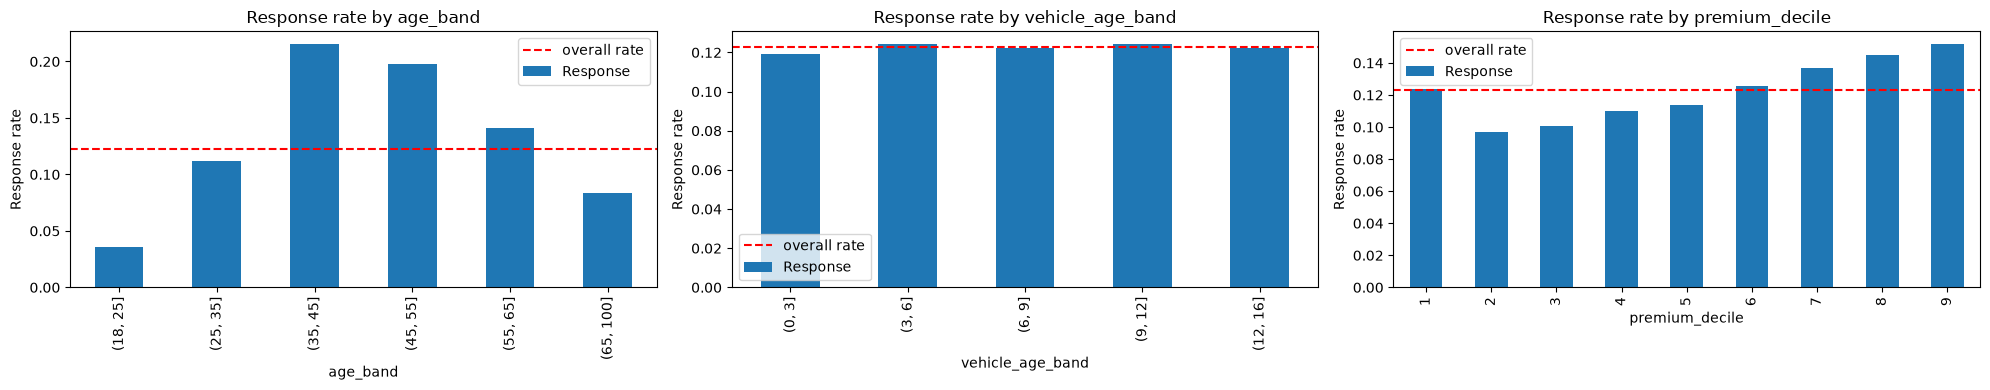

In [24]:
train["age_band"] = pd.cut(train["age"], [18, 25, 35, 45, 55, 65, 100])
train["vehicle_age_band"] = pd.cut(train["vehicle_age"], [0, 3, 6, 9, 12, 16])
train["premium_decile"] = pd.qcut(train["Annual_Premium"], 10, labels=False, duplicates="drop") + 1

fig, axes = plt.subplots(1, 3, figsize=(20, 4))
for ax, col in zip(axes, ["age_band", "vehicle_age_band", "premium_decile"]):
    rate = train.groupby(col, observed=True)["Response"].mean()
    rate.plot(kind="bar", ax=ax, title="Response rate by " + col)
    ax.set_ylabel("Response rate")
    ax.axhline(train["Response"].mean(), color="red", linestyle="--", label="overall rate")
    ax.legend()
plt.tight_layout()
plt.show()

The red dashed line is the overall response rate.

**Insight:**
- **Age:** the response rate rises from about 4% at ages 18 to 25 and 11% at 25 to 35 to a peak of about 22% at 35 to 45 and 20% at 45 to 55, then falls to about 14% at 55 to 65 and 8% above 65. The pattern is hump-shaped, so Logistic Regression needs age bands or a non-linear term, while tree models handle it directly. Age is also related to vehicle damage and previous insurance (see 4.6), so part of this pattern may come from those features.
- **Vehicle age:** the rate is about 12% in every band, so vehicle age has essentially no signal on its own.
- **Premium:** the rate dips to about 10% in decile 2 and climbs to about 15% in decile 9, a mild upward trend. Decile 1 (about 12%) includes the large group at the minimum premium of 2,630.

#### 4.4.4 High-cardinality features: sub-county and agent

In [25]:
for col in ["Customer_Residence_Sub_County", "Agent_name"]:
    g = train.groupby(col)["Response"].agg(rate="mean", customers="count")
    g = g[g["customers"] >= 200].sort_values("rate")
    print(f"{col}: {train[col].nunique()} groups, {len(g)} with at least 200 customers")
    print(f"  response rate ranges from {g['rate'].min():.3f} to {g['rate'].max():.3f} "
          f"(standard deviation {g['rate'].std():.3f}, overall {train['Response'].mean():.3f})")
    print("  Lowest 5 and highest 5:")
    display(pd.concat([g.head(5), g.tail(5)]).round(3))
    print()

Customer_Residence_Sub_County: 53 groups, 52 with at least 200 customers
  response rate ranges from 0.041 to 0.187 (standard deviation 0.033, overall 0.123)
  Lowest 5 and highest 5:


,rate,customers
Customer_Residence_Sub_County,,
KAPSERET,0.041,685
NAKURU NORTH,0.042,2110
TURKANA WEST,0.060,3739
RONGAI,0.064,1126
MALINDI,0.064,8711
KILIFI SOUTH,0.153,1694
SAMBURU,0.159,1292
KWANZA,0.162,1539
BUMULA,0.187,1707



Agent_name: 155 groups, 39 with at least 200 customers
  response rate ranges from 0.021 to 0.317 (standard deviation 0.083, overall 0.123)
  Lowest 5 and highest 5:


,rate,customers
Agent_name,,
Gitonga Mwangi,0.021,18510
Obiero Ochieng,0.029,114607
Kibet Makori,0.032,3347
Otieno Kirima,0.034,912
Maina Kiarie,0.052,269
Nyaga Kibet,0.270,5705
Nyambura Kathuri,0.281,420
Muthoni Gitau,0.296,442
Karanja Wanjala,0.301,2446


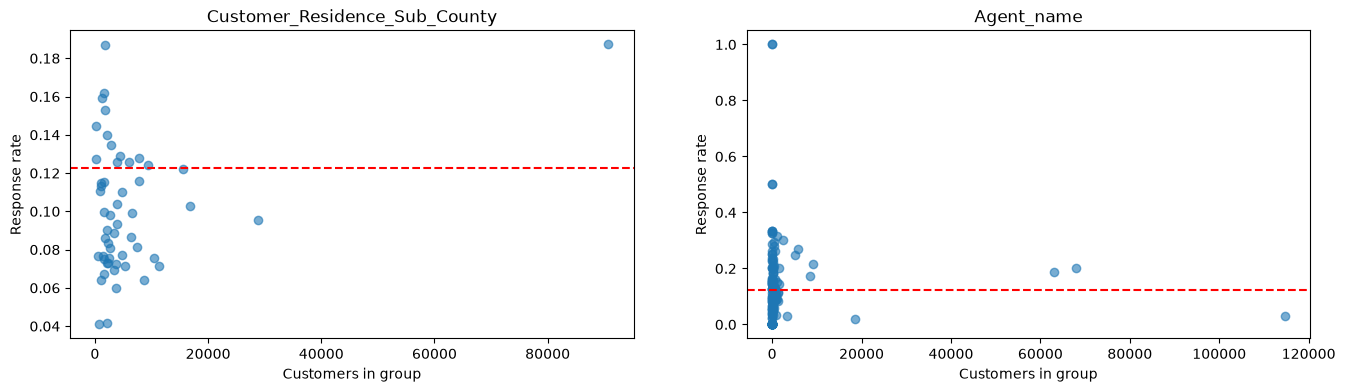

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, col in zip(axes, ["Customer_Residence_Sub_County", "Agent_name"]):
    g = train.groupby(col)["Response"].agg(rate="mean", customers="count")
    ax.scatter(g["customers"], g["rate"], alpha=0.6)
    ax.axhline(train["Response"].mean(), color="red", linestyle="--")
    ax.set_xlabel("Customers in group")
    ax.set_ylabel("Response rate")
    ax.set_title(col)
plt.show()

Small groups naturally scatter more (left side of each chart), so a wide spread among small groups is not by itself a real effect. This is why the target encoder uses smoothing.

**Insight:**
- **Sub-county:** response rates range from 4.1% (Kapseret, 685 customers) to 18.7% (Embakasi, 90,693 customers, and Bumula, 1,707 customers), with a standard deviation of 0.033. Embakasi alone is 28% of all customers and responds well above the overall 12.3%, so sub-county carries real signal.
- **Agent:** only 39 of the 155 agents have at least 200 customers. Most agents have a handful of customers, and their rates jump to 0%, 33%, 50% or 100%, which is noise (see the scatter). Among the 39 larger agents the rate ranges from 2.1% (Gitonga Mwangi, 18,510 customers) to 31.7% (Mariga Kipngetich, 1,043 customers), a standard deviation of 0.083, more than twice the sub-county spread.
- The spread is wide even for the biggest agents: one agent has 114,607 customers (35% of all) at 2.9%, while two others, with about 63,000 and 68,000 customers, respond at about 19 to 20%. So agent either has a genuine effect or acts as a proxy for the kind of customer or region each agent serves.
- **Risk:** this is the agent leakage and proxy risk named in the proposal. It needs two tests: does the agent effect remain after controlling for `Vehicle_Damage` and `Previously_Insured`, and do model performance and SHAP change much when agent is dropped?

### 4.5 Time structure

,policies,response_rate,previously_insured_rate,mean_premium
Life_policy_start_date,,,,
2023-03,8927,0.122,0.455,30691.195
2023-04,33163,0.121,0.460,30553.978
2023-05,34721,0.122,0.460,30662.900
2023-06,33391,0.125,0.460,30457.299
2023-07,34795,0.121,0.458,30549.852
2023-08,34734,0.124,0.457,30511.754
2023-09,33679,0.124,0.456,30611.600
2023-10,34738,0.121,0.460,30521.037
2023-11,33673,0.122,0.456,30503.260


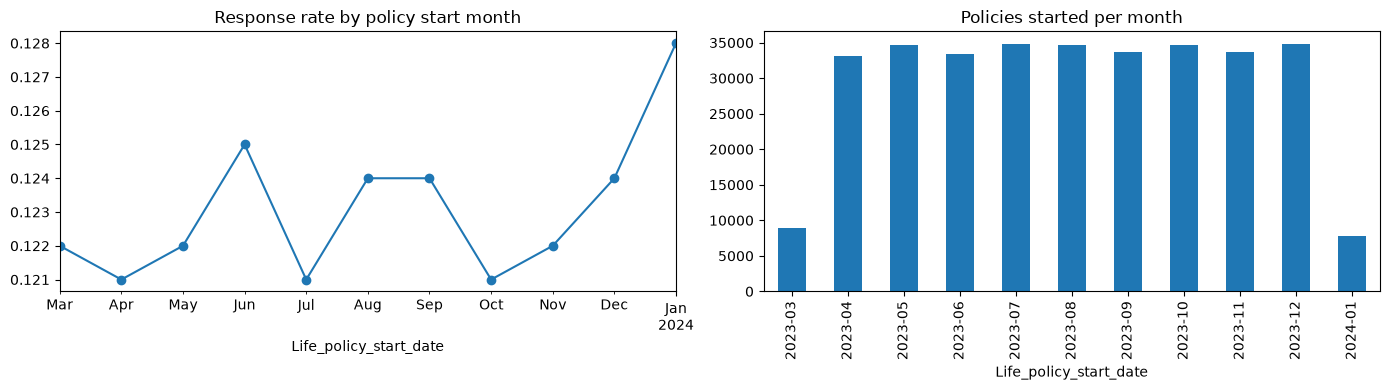

In [27]:
period = train["Life_policy_start_date"].dt.to_period("M")
monthly = train.groupby(period).agg(
    policies=("Response", "size"),
    response_rate=("Response", "mean"),
    previously_insured_rate=("Previously_Insured", "mean"),
    mean_premium=("Annual_Premium", "mean"),
).round(3)
display(monthly)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
monthly["response_rate"].plot(marker="o", ax=axes[0], title="Response rate by policy start month")
monthly["policies"].plot(kind="bar", ax=axes[1], title="Policies started per month")
plt.tight_layout()
plt.show()

**Insight:** The response rate is stable across months, between 12.1% and 12.8%. The mix is just as steady: the share of previously insured customers stays between 45.3% and 46.0%, and the mean premium between about 30,460 and 30,720. Each full month has roughly 33,000 to 35,000 policies, while March 2023 (8,927) and January 2024 (7,794) are partial months, so their rates rest on fewer customers. No trend or drift is visible in these summaries.

#### 4.5.1 Preview of the temporal split (train / validation / test by policy start date)

In [28]:
dates = train["Life_policy_start_date"]
cut_1, cut_2 = dates.quantile(0.70), dates.quantile(0.85)
split = np.where(dates <= cut_1, "1_train", np.where(dates <= cut_2, "2_validation", "3_test"))

preview = train.groupby(split).agg(
    rows=("Response", "size"),
    response_rate=("Response", "mean"),
    previously_insured_rate=("Previously_Insured", "mean"),
    first_date=("Life_policy_start_date", "min"),
    last_date=("Life_policy_start_date", "max"),
).round(4)
display(preview)

,rows,response_rate,previously_insured_rate,first_date,last_date
1_train,227964,0.1227,0.4583,2023-03-24,2023-10-13
2_validation,48394,0.1210,0.4588,2023-10-14,2023-11-25
3_test,48108,0.1250,0.4557,2023-11-26,2024-01-07


This is only a preview. The real split is done in `data_ingestion.py`, and the sealed test window is scored once at the end.

**Insight:** The earliest 70% of policies (24 March to 13 October 2023) give 227,964 training rows with a response rate of 12.27%. The next 15% (14 October to 25 November) give 48,394 validation rows at 12.10%, and the latest 15% (26 November 2023 to 7 January 2024) give 48,108 sealed test rows at 12.50%. The windows are very similar in response rate and in the share of previously insured customers (45.8%, 45.9% and 45.6%), so the base rate shows no drift and the temporal split will probably give results close to a random split. Drift in how the features relate to the response can only be checked by comparing model performance across the windows, and the report should say plainly if none appears.

### 4.6 Correlation and pairplot

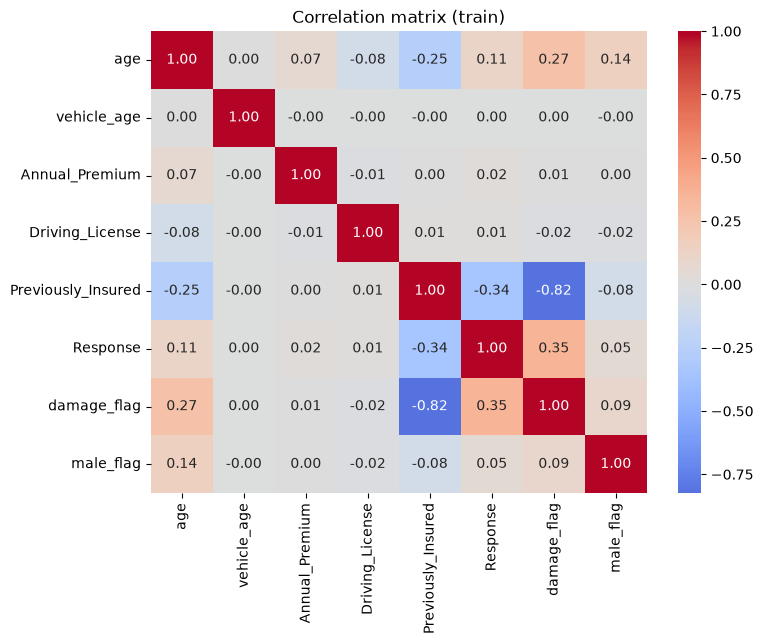

In [29]:
corr_df = train[["age", "vehicle_age", "Annual_Premium", "Driving_License", "Previously_Insured", "Response"]].copy()
corr_df["damage_flag"] = (train["Vehicle_Damage"] == "Yes").astype(int)
corr_df["male_flag"] = (train["Gender"] == "Male").astype(int)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (train)")
plt.show()

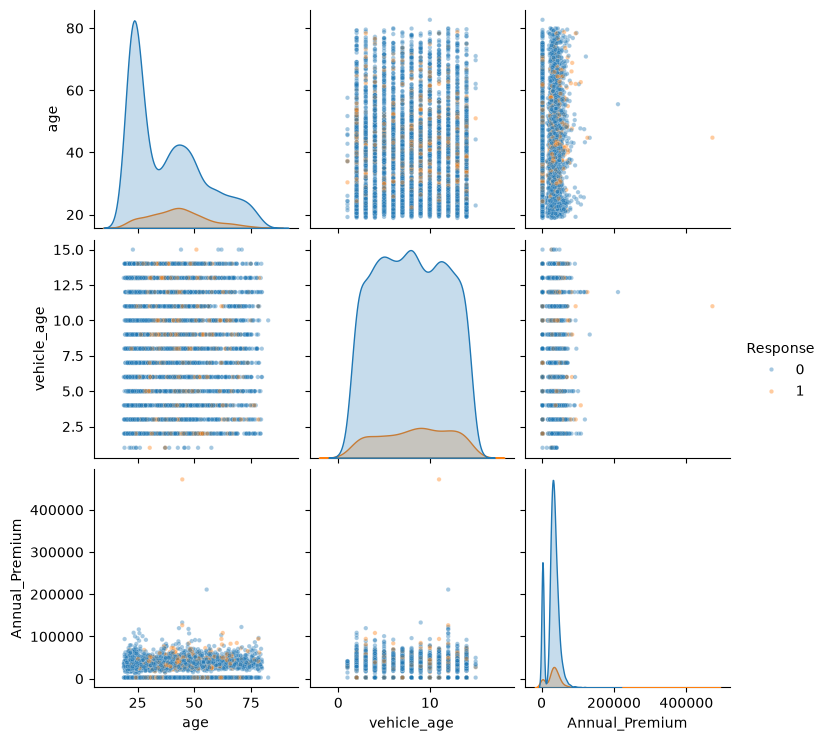

In [30]:
sample = train.sample(5000, random_state=42)
sns.pairplot(sample[numeric_features + ["Response"]], hue="Response", plot_kws={"alpha": 0.4, "s": 10})
plt.show()

The pairplot uses a random sample of 5,000 rows, because plotting all rows would freeze the notebook.

**Insight:**
- `Response` is most strongly related to `damage_flag` (r = 0.35) and `Previously_Insured` (r = -0.34), then `age` (r = 0.11) and gender (r = 0.05). Premium (0.02), `Driving_License` (0.01) and `vehicle_age` (0.00) show almost no linear relationship.
- Age has a low correlation even though it clearly matters (4.4.3), because its effect is hump-shaped and correlation only captures straight-line relationships.
- `Previously_Insured` and vehicle damage are strongly related to each other (r = -0.82): of the customers who already have insurance, 94% report no damage. This is a multicollinearity concern for Logistic Regression (unstable coefficients, so use regularisation and interpret with care) but not for tree models.
- Age is moderately related to damage (r = 0.27) and previous insurance (r = -0.25). Vehicle age is unrelated to every other feature.

### 4.7 Train vs test distributions

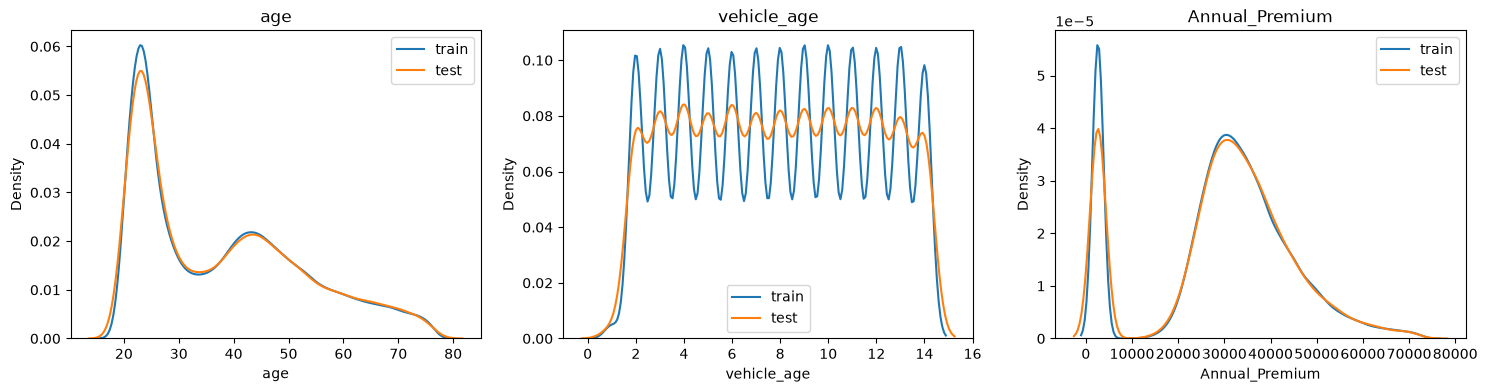

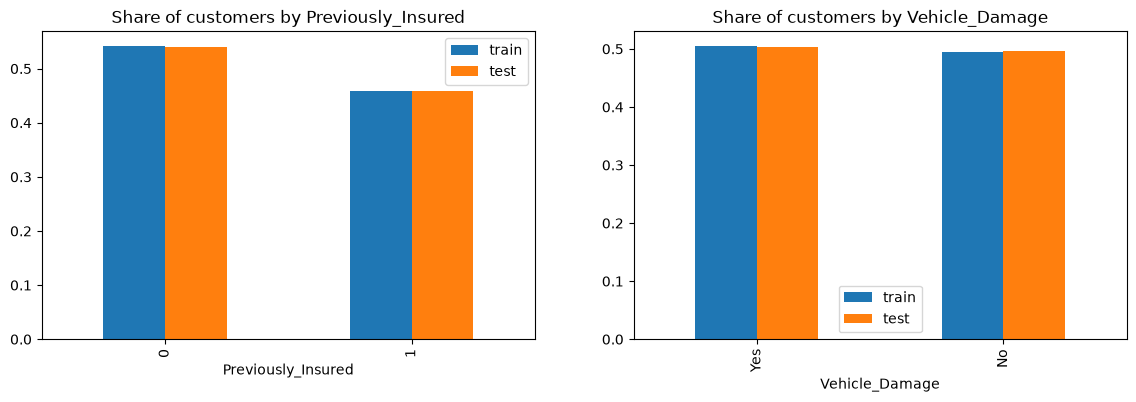

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, numeric_features):
    cap = train[col].quantile(0.99)
    sns.kdeplot(train.loc[train[col] <= cap, col], label="train", ax=ax)
    sns.kdeplot(test.loc[test[col] <= cap, col], label="test", ax=ax)
    ax.set_title(col)
    ax.legend()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ["Previously_Insured", "Vehicle_Damage"]):
    share = pd.DataFrame({"train": train[col].value_counts(normalize=True),
                          "test": test[col].value_counts(normalize=True)})
    share.plot(kind="bar", ax=ax, title="Share of customers by " + col)
plt.show()

**Insight:** The age and premium distributions of train and test overlap almost exactly. The vehicle age curves differ only in the height of their wiggles, most likely because the smaller test sample is smoothed more, and both are flat from 2 to 14 years. The shares of `Previously_Insured` (54% / 46%) and `Vehicle_Damage` (50% / 50%) are practically identical in both files. On these features the test file looks like the training data, so scoring it is a fair use of the model and no drift warning is needed for the predictions.

## 5) Conclusions and pre-processing decisions

### 5.1 What the exploratory analysis shows
- **Target:** 12.3% of customers are interested, a 7.1 : 1 imbalance.
- **Strongest signals:** `Vehicle_Damage` (23.8% vs 0.5%) and `Previously_Insured` (22.6% vs 0.1%), then age (4.4.1, 4.6).
- **Interaction:** customers with past damage who are not insured respond at 25.0%. They are 48% of customers and about 97% of all interested customers (4.4.2).
- **Age, vehicle age, premium:** age is hump-shaped, peaking at about 20 to 22% between ages 35 and 55. Vehicle age has no signal (flat at about 12%). Premium shows a mild upward trend, a spike at the minimum value of 2,630, and a thin tail up to 540,165 (4.2 to 4.4.3).
- **Gender:** 13.8% for male vs 10.5% for female, the base-rate gap for the fairness check (4.4.1).
- **Sub-county and agent:** sub-county rates range from 4.1% to 18.7%. Among agents with at least 200 customers they range from 2.1% to 31.7%, and the spread persists among the largest agents, so agent is a leakage and proxy risk that must be tested (4.4.4).
- **Time:** monthly response rates stay between 12.1% and 12.8%, and the three split windows are 12.27%, 12.10% and 12.50%. No drift is visible in the base rate or the feature mix (4.5, 4.5.1).
- **Train vs test:** same policy period, near-identical distributions, no unseen categories and no shared ids (3.9, 4.7).

### 5.2 Decisions for the pipeline

| Issue | Evidence | Decision |
|---|---|---|
| Dates stored as text | 3.3 | Parse with an explicit format. Derive `age` and `vehicle_age` from the policy start date only, so nothing uses information from after the policy began |
| Repeated customer ids | 3.2, 3.9 | Drop `id` from the features and never use it for joins or deduplication (70 repeats in train, 13 in test, none shared) |
| Near-constant `Driving_License` | 3.5, 4.4.1 | Keep for the baseline, and drop it if importance and SHAP show it adds nothing |
| Premium skew, outliers and a floor value | 3.5, 4.3, 4.4.3 | Leave as is for tree models. Cap at the 99th percentile or log-transform for Logistic Regression. Check the 2,630 value and consider a flag for it |
| Hump-shaped age effect | 4.4.3 | Use age bands or a spline for Logistic Regression. Tree models use raw age |
| Vehicle age shows no signal | 4.2, 4.4.3, 4.6 | Keep in the first models and drop it if importance stays near zero |
| `Previously_Insured` and vehicle damage are collinear (r = -0.82) | 4.4.2, 4.6 | Keep both because their interaction carries the signal. Regularise Logistic Regression and add an interaction term. Tree models need no change |
| High-cardinality sub-county (53) and agent (155) | 3.4, 4.4.4 | Target-encode inside the cross-validation folds with smoothing, because most agents have very few customers. Unseen categories fall back to the global response rate |
| Agent may act as a proxy | 4.4.4 | Compare models with and without agent, check the agent effect inside the damage and not-insured segment, and report SHAP |
| Class imbalance | 3.6, 4.1 | PR-AUC as the main metric, class weights, and a decision threshold chosen on validation data |
| Short time window with a stable base rate | 3.7, 4.5, 4.5.1 | Chronological 70 / 15 / 15 split by policy start date. Compare performance across the windows and report honestly if no drift appears |
| Unlabelled test file | 3.9, 4.7 | Same policy period as train, so it is used only for the final scoring and not as a drift test |